# Ejercicio 1 — Campañas de marketing con creadores de contenido

## Índice

**1.1 Exploración y representación**

1. [Problema y objetivo](#1.-Problema-y-objetivo)
2. [Datos y selección de variables](#2.-Datos-y-selección-de-variables)
3. [Análisis exploratorio](#3.-Análisis-exploratorio)
4. [PCA](#4.-PCA)
5. [Conclusiones del 1.1](#5.-Conclusiones-del-1.1)

**1.2 Red de Kohonen**

6. [Implementación](#6.-Implementación)
7. [Selección de hiperparámetros](#7.-Selección-de-hiperparámetros)
8. [Grilla de neuronas y matriz U](#8.-Grilla-de-neuronas-y-matriz-U)
9. [Interpretación de las regiones](#9.-Interpretación-de-las-regiones)
10. [Conclusiones del 1.2](#10.-Conclusiones-del-1.2)

## 1. Problema y objetivo

La agencia elige creadores por cantidad de seguidores y sus campañas no recuperan la inversión. Cada cliente (refugios de perros, ropa de fútbol, belleza y materiales de arte) necesita una audiencia y un contenido distintos. En el 1.1 se eligen las variables que describen a un creador, se aplica **PCA** para ver cuántas direcciones independientes hay en los datos y se interpretan las componentes. En el 1.2 se agrupan los creadores con una **red de Kohonen**.

El código está en módulos: `preprocessing.py` (selección y estandarización, que reutilizan Kohonen y Oja), `eda.py`, `pca.py` (PCA propio con numpy), `kohonen.py` (red de Kohonen propia) y `plots.py`.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Permite ejecutar el notebook tanto desde la raíz del repositorio como desde TP4.
cwd = Path.cwd()
tp4_dir = cwd / "TP4" if (cwd / "TP4" / "pca.py").exists() else cwd
if str(tp4_dir) not in sys.path:
    sys.path.insert(0, str(tp4_dir))

import eda
import plots
from pca import PCA, broken_stick, retention_criteria
from preprocessing import (FEATURE_GROUPS, check_derived, composition_sums, find_data_path,
                           load_creators, prepare_features)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plots.set_style()

DATA_PATH = find_data_path()
df = load_creators(DATA_PATH)
df.head()

,creator_id,name,followers,average_reach,average_impressions,average_video_views,monthly_posts,argentina_audience_pct,estimated_argentina_reach,non_follower_reach_pct,...,topic_art_pct,content_tutorial_pct,content_review_pct,content_entertainment_pct,content_showcase_pct,average_caption_words,average_watch_time_seconds,video_posts_pct,short_form_posts_pct,trend_posts_pct
0,INF001,@mateconideas,775589,245722,369678,176505,26,83.190,204416,55.950,...,15.300,2.780,13.730,68.360,15.130,56.190,18.850,58.430,60.030,49.200
1,INF002,@brillourbano,638718,235620,281643,180650,15,29.780,70168,77.770,...,6.930,9.920,10.890,69.300,9.890,54.050,20.760,66.490,70.470,54.140
2,INF003,@huellasyconsejos,13235,4193,6339,2378,10,94.430,3959,30.100,...,15.290,59.480,27.540,0.380,12.600,180.740,31.070,24.950,21.890,13.050
3,INF004,@pincelcotidiano,333692,98820,155470,78156,15,42.100,41603,80.570,...,70.190,24.830,24.010,11.130,40.030,66.940,19.080,66.010,72.680,56.460
4,INF005,@tribunacreativa,461892,178805,210636,138941,7,68.300,122124,82.100,...,10.440,8.250,2.840,85.910,3.000,50.880,20.940,66.840,66.690,54.030


## 2. Datos y selección de variables

In [2]:
print(f"Creadores: {len(df)} | columnas: {df.shape[1]}")
print(f"Valores faltantes: {int(df.isna().sum().sum())} | filas duplicadas: {int(df.duplicated().sum())}")
display(check_derived(df))
display(composition_sums(df))

Creadores: 50 | columnas: 33
Valores faltantes: 0 | filas duplicadas: 0


,fórmula,error máx.,error relativo máx.
columna,,,
price_ars,price_usd · 1500,0.000,0.000
estimated_argentina_reach,average_reach · argentina_audience_pct / 100,0.499,0.000
total_engagement_per_1000,likes + comments + saves + shares (por 1000),0.000,0.000
organic_posts_pct,100 − sponsored_posts_pct,0.000,0.000


,min,max
topic_*,100.000,100.000
content_*,100.000,100.000
sponsored + organic,100.000,100.000


No hay faltantes ni duplicados. Las cuatro columnas derivadas cumplen su fórmula (`estimated_argentina_reach` difiere en menos de 0,5 cuentas por redondeo), y `topic_*`, `content_*` y `sponsored`/`organic` suman exactamente 100.

| Decisión | Variables | Motivo |
|---|---|---|
| Se excluyen | `creator_id`, `name` | Identificadores. |
| Se excluyen | `price_ars`, `organic_posts_pct`, `total_engagement_per_1000`, `estimated_argentina_reach` | Son fórmulas exactas de otras variables que ya están. |
| Se conservan | las cuatro `topic_*` y las cuatro `content_*` | Cada temática es un cliente. Aunque cada grupo suma 100, para PCA eso sólo produce un autovalor nulo. |

Quedan **27 variables**. Las cinco de escala (`followers`, `average_reach`, `average_impressions`, `average_video_views`, `price_usd`) se pasan a **log10**, y luego todas se estandarizan.

In [3]:
data = prepare_features(df)
features = data.features
raw = df[features]

for group, columns in FEATURE_GROUPS.items():
    print(f"{group:<18} ({len(columns)}): {', '.join(columns)}")

Alcance y precio   (7): followers, average_reach, average_impressions, average_video_views, price_usd, monthly_posts, non_follower_reach_pct
Audiencia          (1): argentina_audience_pct
Interacción        (5): likes_per_1000, comments_per_1000, saves_per_1000, shares_per_1000, profile_visits_per_1000
Comercial          (1): sponsored_posts_pct
Temática           (4): topic_football_pct, topic_makeup_pct, topic_dogs_pct, topic_art_pct
Tipo de contenido  (4): content_tutorial_pct, content_review_pct, content_entertainment_pct, content_showcase_pct
Formato            (5): average_caption_words, average_watch_time_seconds, video_posts_pct, short_form_posts_pct, trend_posts_pct


## 3. Análisis exploratorio

,media,desvío,min,mediana,max,cv,asimetría,curtosis
followers,"221,587.140","208,330.810","9,604.000","198,476.000","775,589.000",0.940,0.985,0.191
average_reach,"81,608.760","81,654.621","2,786.000","54,935.500","268,518.000",1.001,0.991,-0.225
average_impressions,"114,068.400","112,361.856","3,585.000","81,609.500","369,678.000",0.985,0.965,-0.186
average_video_views,"61,207.460","63,364.196","1,719.000","41,113.500","206,530.000",1.035,0.990,-0.304
price_usd,"1,700.803","1,728.144",75.000,"1,061.565","6,334.710",1.016,1.205,0.625
monthly_posts,15.760,6.416,5.000,15.000,28.000,0.407,0.227,-0.887
non_follower_reach_pct,55.629,17.757,19.330,56.220,82.100,0.319,-0.253,-0.943
argentina_audience_pct,52.644,22.320,19.550,48.580,94.430,0.424,0.313,-1.256
likes_per_1000,42.569,6.906,22.280,43.455,55.100,0.162,-0.807,0.819
comments_per_1000,4.460,1.405,0.790,4.350,7.280,0.315,-0.072,0.043


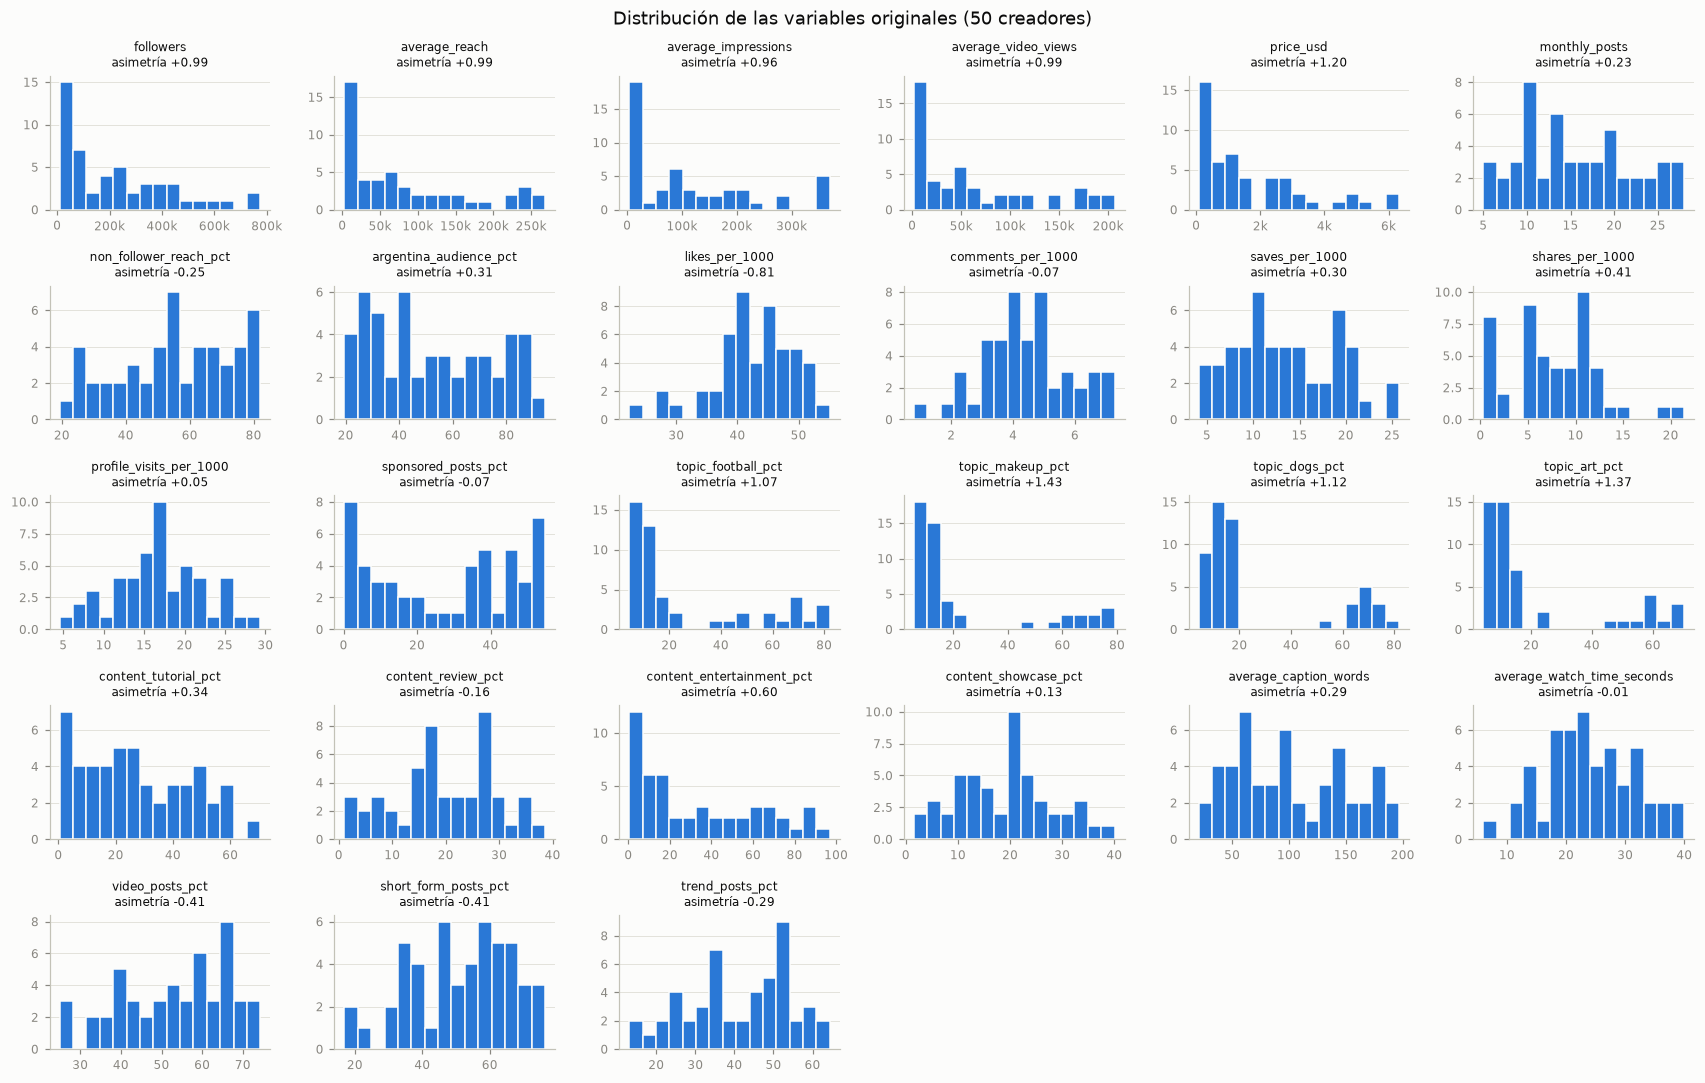

In [4]:
display(eda.describe(raw))
plots.plot_distributions(raw)
plt.show()

- **Escalas muy distintas.** `followers` llega a ~775.000 y `comments_per_1000` no pasa de 7. Por eso se estandariza y el PCA se hace sobre la matriz de correlación.
- **Variables de escala con cola a derecha.** Son conteos y precios que abarcan dos órdenes de magnitud y cuyas diferencias son multiplicativas. Con log10 la asimetría baja de ≈ +1 a ≈ −0,35, y unos pocos creadores masivos dejan de concentrar la varianza.
- **Temáticas bimodales.** Cada creador tiene una temática dominante (≈ 65 % de sus publicaciones). Por eso la regla 1,5·IQR marca como "atípicos" a los 11 especialistas en maquillaje y a los 11 en arte. Es estructura de los datos, no error: **no se descarta ningún creador**.

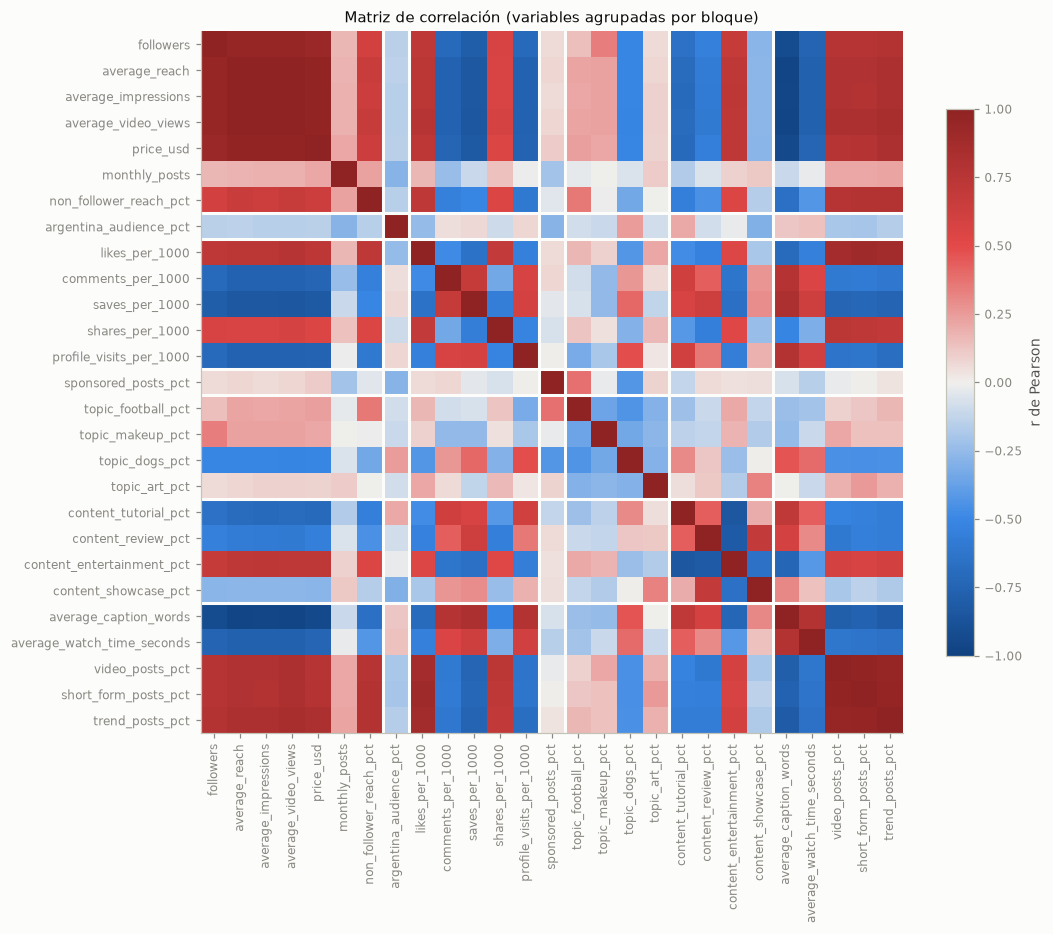

,variable 1,variable 2,r
0,average_reach,average_video_views,0.997
1,average_impressions,average_video_views,0.988
2,average_reach,average_impressions,0.987
3,video_posts_pct,short_form_posts_pct,0.971
4,short_form_posts_pct,trend_posts_pct,0.961
5,video_posts_pct,trend_posts_pct,0.952
6,followers,average_reach,0.918
7,average_impressions,price_usd,0.915
8,followers,average_impressions,0.912
9,average_video_views,price_usd,0.908


In [5]:
plots.plot_correlation(data.transformed, FEATURE_GROUPS)
plt.show()
display(eda.correlated_pairs(raw, threshold=0.9))

- **Bloques casi redundantes:** `average_reach`, `average_impressions` y `average_video_views` tienen r > 0,98 entre sí, y con `followers` y `price_usd` r > 0,9. Lo mismo pasa con `video_posts_pct`, `short_form_posts_pct` y `trend_posts_pct` (r > 0,95).
- **Dos perfiles opuestos (patrón de tablero):** tamaño, formato corto, likes y entretenimiento por un lado; guardados, comentarios, visitas al perfil, textos largos y tutoriales por el otro.

Las variables redundantes se dejan a propósito: que PCA las agrupe es lo que justifica la reducción.

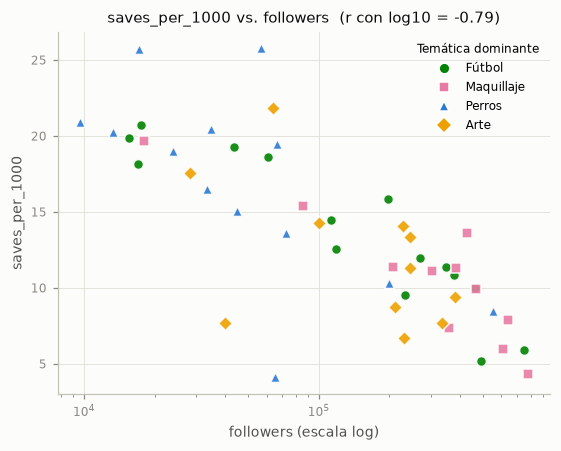

In [6]:
plots.plot_reach_vs_depth(df, data.topic, ["saves_per_1000"])
plt.show()

**A más seguidores, menos guardados por cada 1000 cuentas alcanzadas.** Elegir sólo por `followers` selecciona audiencias que miran pero no se involucran. Además, en cada temática hay creadores grandes y chicos: tamaño y temática son ejes distintos.

## 4. PCA

`pca.PCA` descompone la matriz de correlación $C = \frac{1}{n} Z^\top Z$ con `np.linalg.eigh`. Las componentes son los autovectores ordenados por autovalor, los scores son $ZV$ y las cargas son $V\sqrt{\Lambda}$ (la correlación entre cada variable y cada componente). Se valida contra sklearn.

Máx. diferencia en varianza explicada vs. sklearn: 1.4e-16
Últimos autovalores: [0.003  0.0002 0.     0.    ]


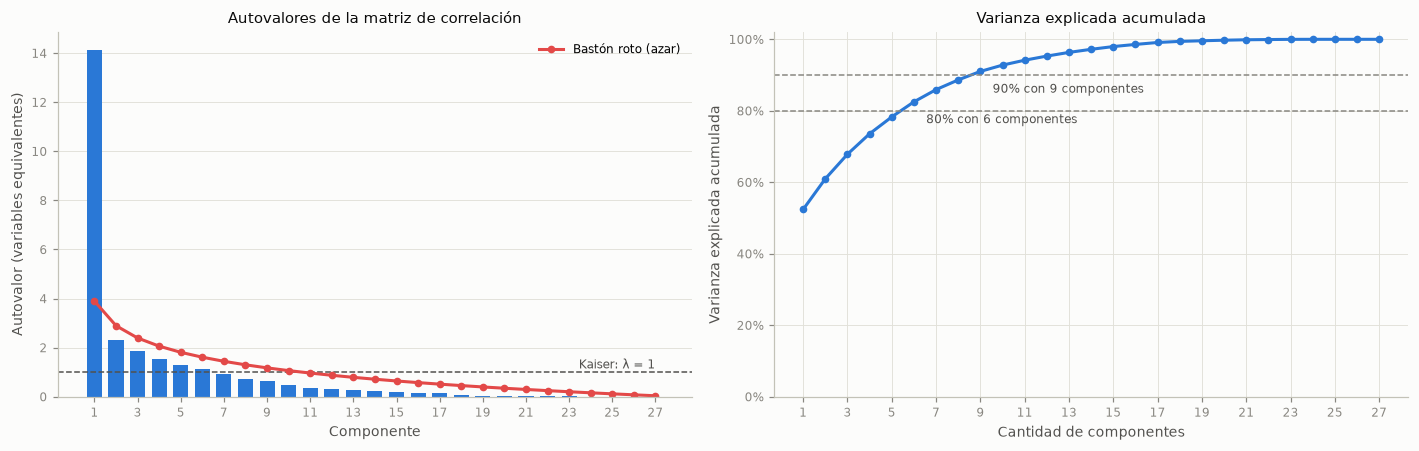

,componentes
Kaiser (λ > 1),6
Bastón roto,1
Varianza acumulada ≥ 80%,6
Varianza acumulada ≥ 90%,9


In [7]:
X = data.X
pca = PCA().fit(X)
scores = pca.transform(X)
eigenvalues = pca.eigenvalues_
explained = pca.explained_variance_ratio_

from sklearn.decomposition import PCA as SklearnPCA

reference = SklearnPCA().fit(X)
print(f"Máx. diferencia en varianza explicada vs. sklearn: {np.abs(reference.explained_variance_ratio_ - explained).max():.1e}")
print(f"Últimos autovalores: {np.round(eigenvalues[-4:], 4)}")

plots.plot_scree(eigenvalues, broken_stick(len(eigenvalues)))
plt.show()
display(retention_criteria(eigenvalues).to_frame())

- Los dos últimos autovalores son **0** (las restricciones "`topic_*` suma 100" y "`content_*` suma 100") y los dos anteriores son **casi 0** (reach, impressions y views son prácticamente la misma variable). El espectro confirma las redundancias del EDA.
- **PC1 sola explica ≈ 52 %** (resume el equivalente a 14 de las 27 variables), y después hay una caída abrupta.
- **Kaiser** y **80 % acumulado** coinciden en **6 componentes** (≈ 82 %). El bastón roto sólo confirma PC1. Con 50 creadores, PC2–PC6 son interpretables pero menos estables.

**La reducción está justificada:** de 27 variables a 6 componentes se conserva ≈ 82 % de la varianza, y las 4 primeras tienen lectura de negocio.

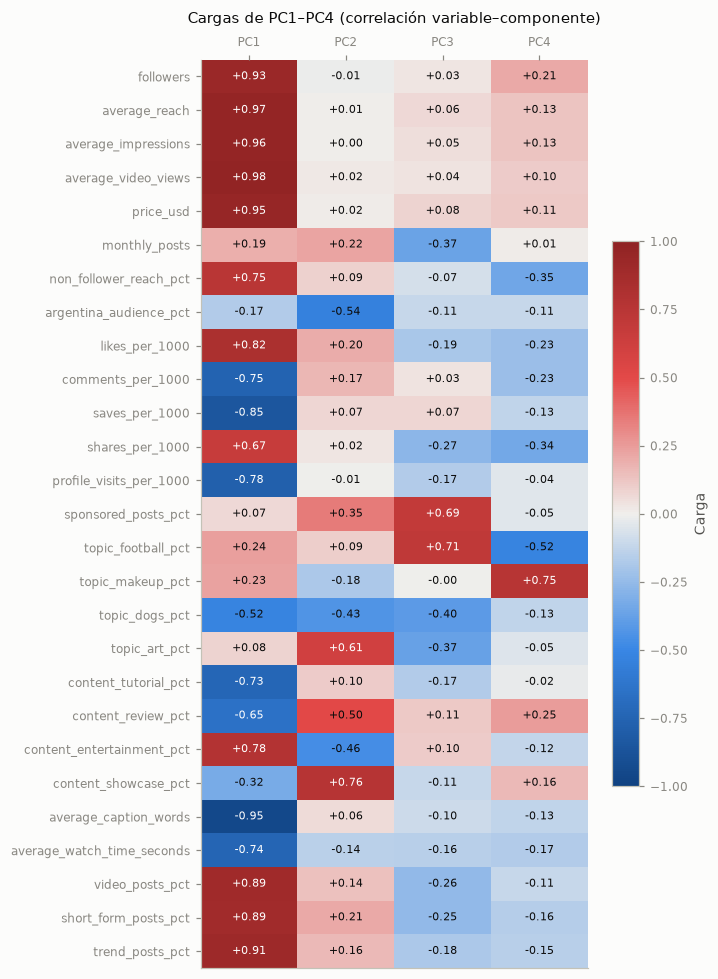

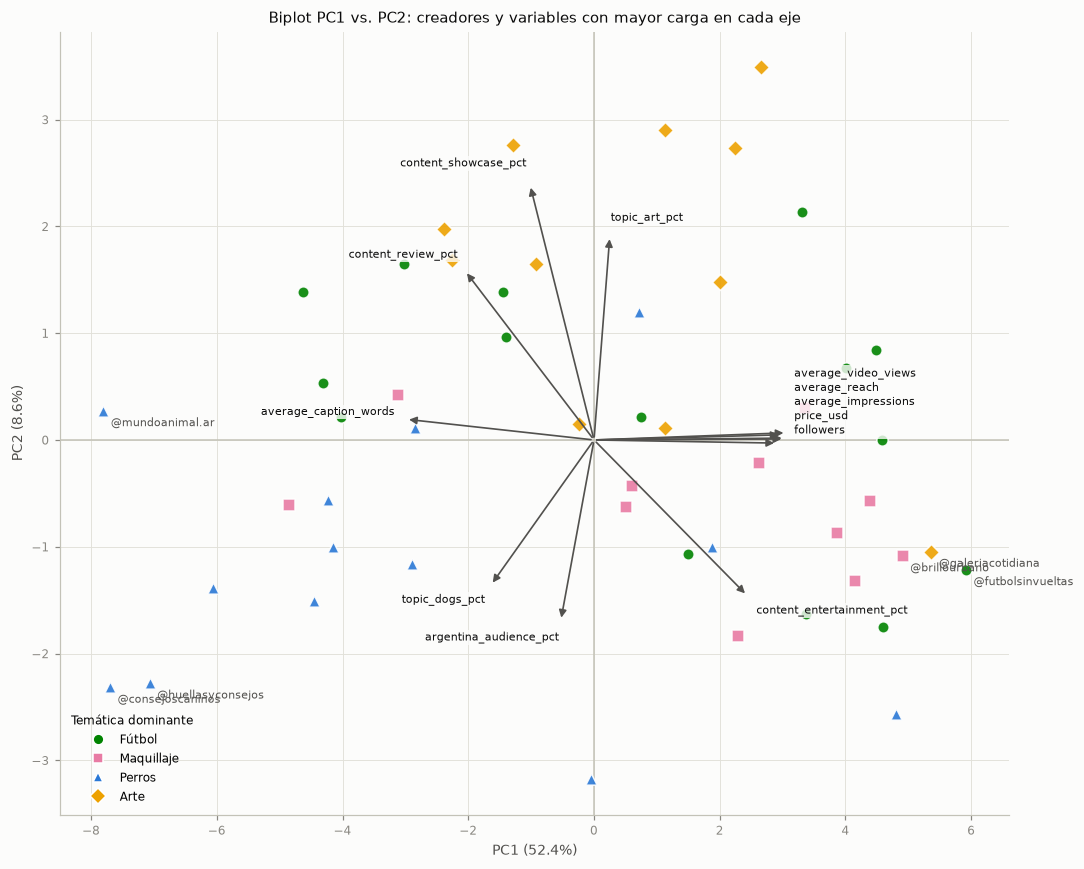

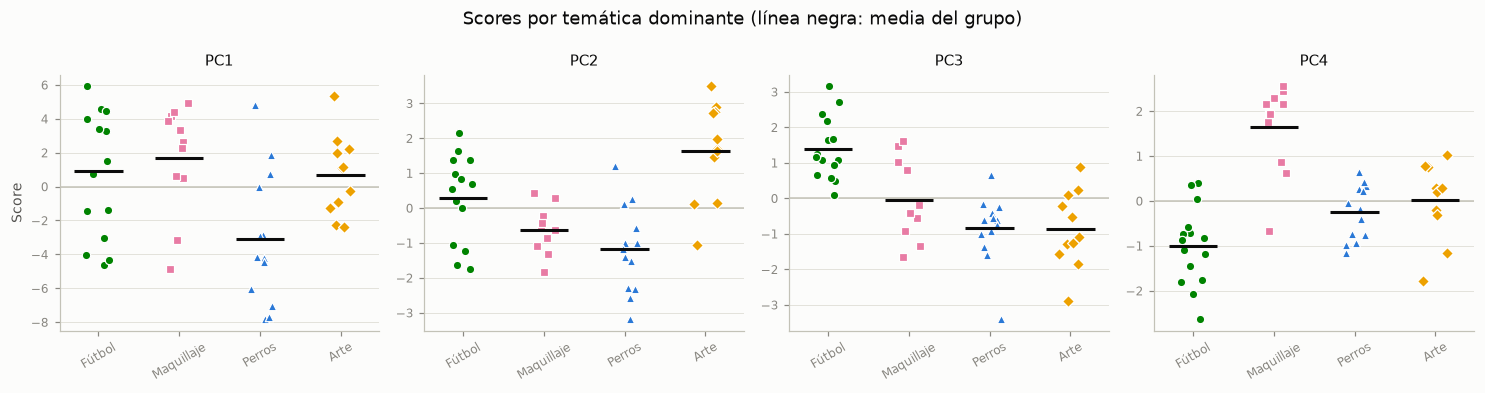

Correlación de PC1 con log10(followers): +0.928


In [8]:
loadings = pca.loadings(features)
plots.plot_annotated_heatmap(loadings.iloc[:, :4], "Cargas de PC1–PC4 (correlación variable–componente)",
                             "Carga", limit=1, figsize=(6.5, 9))
plt.show()
plots.plot_biplot(scores, loadings, data.topic, data.names, pcs=(1, 2), explained=explained)
plt.show()
plots.plot_scores_by_topic(scores, data.topic, n_components=4)
plt.show()
print(f"Correlación de PC1 con log10(followers): {np.corrcoef(scores[:, 0], data.transformed['followers'])[0, 1]:+.3f}")

| Componente | Varianza | Polo positivo | Polo negativo | Lectura |
|---|---|---|---|---|
| **PC1** | 52 % | reach, views, impressions, precio, followers (> 0,9), formato corto, entretenimiento, likes | palabras del texto (−0,95), guardados, visitas al perfil, comentarios, tutoriales | **Alcance masivo ↔ profundidad** |
| **PC2** | 9 % | showcase, arte, reseñas | audiencia argentina, entretenimiento, perros | Separa **arte** |
| **PC3** | 7 % | fútbol, patrocinio | perros, arte, frecuencia | Separa **fútbol** |
| **PC4** | 6 % | maquillaje | fútbol | Separa **maquillaje** |

- PC1 correlaciona 0,93 con log10(followers): **la estrategia actual equivale a ordenar por PC1**, e ignora que el polo opuesto concentra el engagement de mayor intención.
- En los scores por temática, **PC1 tiene mucha dispersión dentro de cada temática** (perros se concentra en el polo profundo), mientras que **las temáticas se separan en PC2–PC4**. Elegir creador implica dos decisiones independientes: temática y tipo de alcance.

## 5. Conclusiones del 1.1

- **Variables:** se usan 27. Se excluyen los identificadores y las 4 columnas derivadas, se aplica log10 a las 5 de escala y se estandariza todo con `preprocessing.prepare_features`, el mismo preprocesamiento que usan Kohonen y Oja.
- **Reducción:** está justificada. Hay dependencias exactas y bloques redundantes, y 6 componentes retienen ≈ 82 % de la varianza.
- **Interpretación:** PC1 (masivo ↔ profundo) resume más de la mitad de la información. PC2–PC4 identifican arte, fútbol y maquillaje.
- **Para el 1.2:** el enunciado pide agrupar "en términos de todas sus variables", así que Kohonen usa las 27 variables estandarizadas, y el biplot PC1–PC2 es la referencia para comparar. Como el bloque de tamaño está sobrerrepresentado, la distancia euclídea queda dominada por PC1.
- **Para el 1.3:** Oja debería converger a PC1, que es casi log10(followers). Elegir el máximo de ese índice reproduciría la estrategia que hoy no funciona.
- **Para las campañas:** elegir por seguidores lleva al polo masivo, que es más caro y tiene menos guardados, comentarios y visitas al perfil. Para un refugio que busca adopciones, el polo profundo y local parece el más adecuado.

## 6. Implementación

`kohonen.Kohonen` implementa un mapa autoorganizado sobre una grilla rectangular de `filas × columnas` neuronas. Cada neurona tiene un vector de pesos (su **prototipo**) en el mismo espacio que los creadores: las 27 variables estandarizadas del 1.1.

1. **Inicialización:** cada prototipo arranca en un creador elegido al azar.
2. **Entrenamiento online:** en cada época se recorren los 50 creadores en orden aleatorio. Para cada creador $x$ se busca la neurona ganadora (BMU), la de prototipo más cercano en distancia euclídea, y se actualizan todas las neuronas:
$$w_j \leftarrow w_j + \eta(t)\, h_j(t)\,(x - w_j), \qquad h_j(t) = \exp\!\left(-\frac{\lVert r_j - r_{\text{BMU}} \rVert^2}{2R(t)^2}\right)$$
   donde $r_j$ es la posición de la neurona en la grilla. La tasa $\eta$ decae exponencialmente de $\eta_0$ a 0,01 y el radio $R$ de $R_0$ a $R_{\text{final}}$.
3. **Métricas:**
   - **Error de cuantización (QE):** distancia media de cada creador a su prototipo. Mide qué tan bien los prototipos representan a los creadores.
   - **Error topográfico (TE):** fracción de creadores cuyas dos neuronas más cercanas no son vecinas en la grilla (se cuentan las 8 que la rodean). Mide si el mapa preserva la vecindad: creadores parecidos deben quedar en neuronas contiguas.
   - **Varianza explicada:** $1 - \text{QE}^2_{\text{medio}} / \text{varianza total}$. Es comparable con la varianza explicada del PCA.

In [9]:
from kohonen import Kohonen, explained_variance, sweep

configs = [{"rows": side, "cols": side, "radius": side / 2, "final_radius": final_radius}
           for side in range(3, 9) for final_radius in (1.0, 0.5, 0.2)]
grid_results = (sweep(X, configs, learning_rate=0.5, epochs=100)
                .rename(columns={"rows": "lado", "final_radius": "radio final"}))

## 7. Selección de hiperparámetros

Primero se varían los dos hiperparámetros que más cambian el resultado: el **tamaño de la grilla** (de 3×3 a 8×8) y el **radio final** de la vecindad. Cada configuración se entrena con 5 semillas, con $\eta_0 = 0{,}5$, $R_0$ igual a la mitad del lado y 100 épocas.

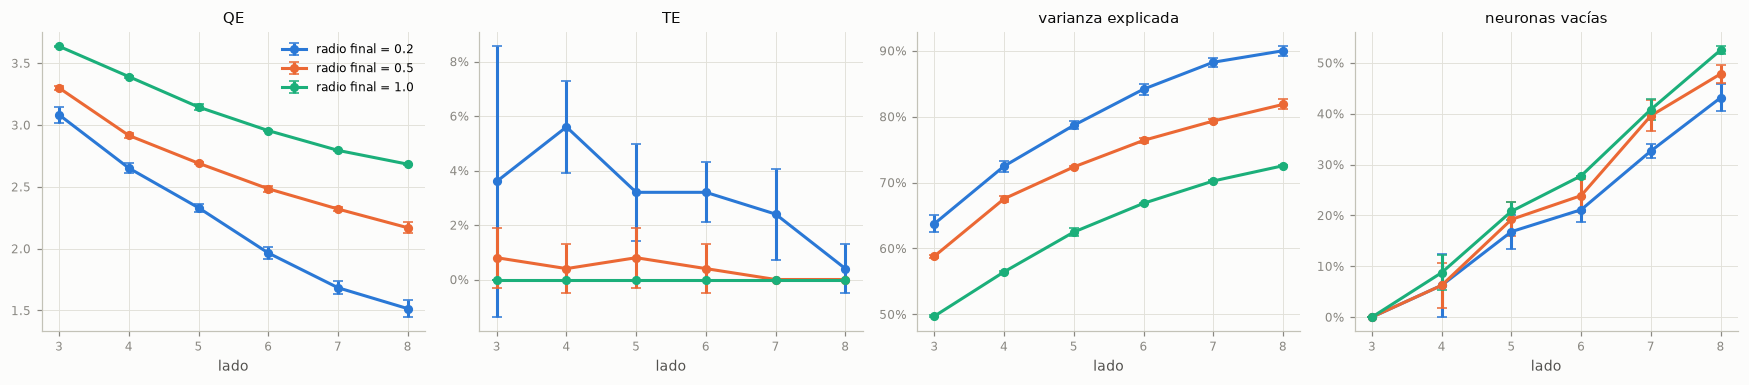

In [10]:
plots.plot_som_sweep(grid_results, x="lado", hue="radio final")
plt.show()

- **El QE no sirve para elegir el tamaño por sí solo**: baja siempre al agregar neuronas. Con 8×8 hay más neuronas (64) que creadores (50), y el mapa tiende a asignar un prototipo por creador.
- **Radio final.** Con 1,0 la vecindad sigue siendo ancha al terminar: el mapa queda rígido y representa mal a los creadores (QE alto, varianza explicada baja). Con 0,2 cada neurona se ajusta sola al final y el mapa empieza a perder orden (TE de 3 a 6 % y más variable entre semillas). **0,5** logra un TE prácticamente nulo con un QE intermedio.
- **Tamaño.** Desde 5×5 cada lado adicional suma poca varianza explicada (+3 a 4 puntos) y muchas neuronas vacías (19 % con 5×5, 24 % con 6×6, 40 % con 7×7). Con 50 creadores, **5×5** deja ≈ 2 creadores por neurona y reproduce ≈ 72 % de la varianza. Las 2 primeras componentes del PCA reproducen 61 % y las 4 primeras 74 %. Con 4×4 se mezclan más las temáticas en una misma neurona.

Con la grilla fijada en 5×5 y radio final 0,5, se varía un hiperparámetro por vez respecto de la configuración elegida:

In [11]:
BASE = {"rows": 5, "cols": 5, "learning_rate": 0.5, "radius": 2.5, "final_radius": 0.5,
        "epochs": 100, "init": "sample"}
variations = {
    "learning_rate": [0.1, 0.5, 0.9],
    "radius": [1.25, 2.5, 5.0],
    "init": ["sample", "pca"],
    "epochs": [25, 50, 100, 200, 400],
}
tables = []
for parameter, values in variations.items():
    fixed = {key: value for key, value in BASE.items() if key != parameter}
    result = sweep(X, [{parameter: value} for value in values], **fixed)
    summary = result.groupby(parameter, sort=False)[["QE", "TE", "varianza explicada"]].agg(["mean", "std"])
    summary.index = pd.MultiIndex.from_product([[parameter], summary.index.astype(str)],
                                               names=["parámetro", "valor"])
    tables.append(summary)
display(pd.concat(tables))

QE          TE       varianza explicada      
                      mean   std  mean   std               mean   std
parámetro     valor                                                  
learning_rate 0.1    2.771 0.038 0.012 0.018              0.708 0.008
              0.5    2.691 0.007 0.008 0.011              0.724 0.001
              0.9    2.669 0.020 0.004 0.009              0.728 0.005
radius        1.25   2.567 0.047 0.020 0.014              0.749 0.009
              2.5    2.691 0.007 0.008 0.011              0.724 0.001
              5.0    2.799 0.045 0.000 0.000              0.701 0.009
init          sample 2.691 0.007 0.008 0.011              0.724 0.001
              pca    2.673 0.032 0.000 0.000              0.727 0.007
epochs        25     2.902 0.033 0.012 0.018              0.680 0.006
              50     2.770 0.018 0.008 0.011              0.708 0.004
              100    2.691 0.007 0.008 0.011              0.724 0.001
              200    2.621 0.009 0.004 0.009              0.737 0.002
              400    2.552 0.021 0.004 0.009              0.750 0.006

- **Tasa de aprendizaje** ($\eta_0$): entre 0,5 y 0,9 casi no hay diferencia. Con 0,1 el mapa se acomoda más lento y el QE sube. Se usa **0,5**.
- **Radio inicial** ($R_0$): un radio más chico baja algo el QE, pero con la mitad del lado (**2,5**) cada actualización alcanza a todo el mapa al comienzo, y eso es lo que lo ordena globalmente. La diferencia es menor al 5 %.
- **Inicialización:** arrancar desde creadores al azar o desde el plano PC1–PC2 da el mismo resultado. Se usa la aleatoria, así el mapa no recibe información del PCA y la comparación con el biplot es independiente.
- **Épocas:** el QE baja poco después de 100 épocas y el TE no cambia. Se usan **100**.

**Configuración final:** grilla 5×5, $\eta_0 = 0{,}5$, $R_0 = 2{,}5$, $R_{\text{final}} = 0{,}5$, 100 épocas. Las métricas varían poco entre semillas (desvíos de QE ≈ 0,01): el mapa es estable, y con otra semilla se obtiene el mismo mapa rotado o espejado.

## 8. Grilla de neuronas y matriz U

QE = 2.686 | TE = 0% | varianza explicada = 72.4% | neuronas vacías = 4/25


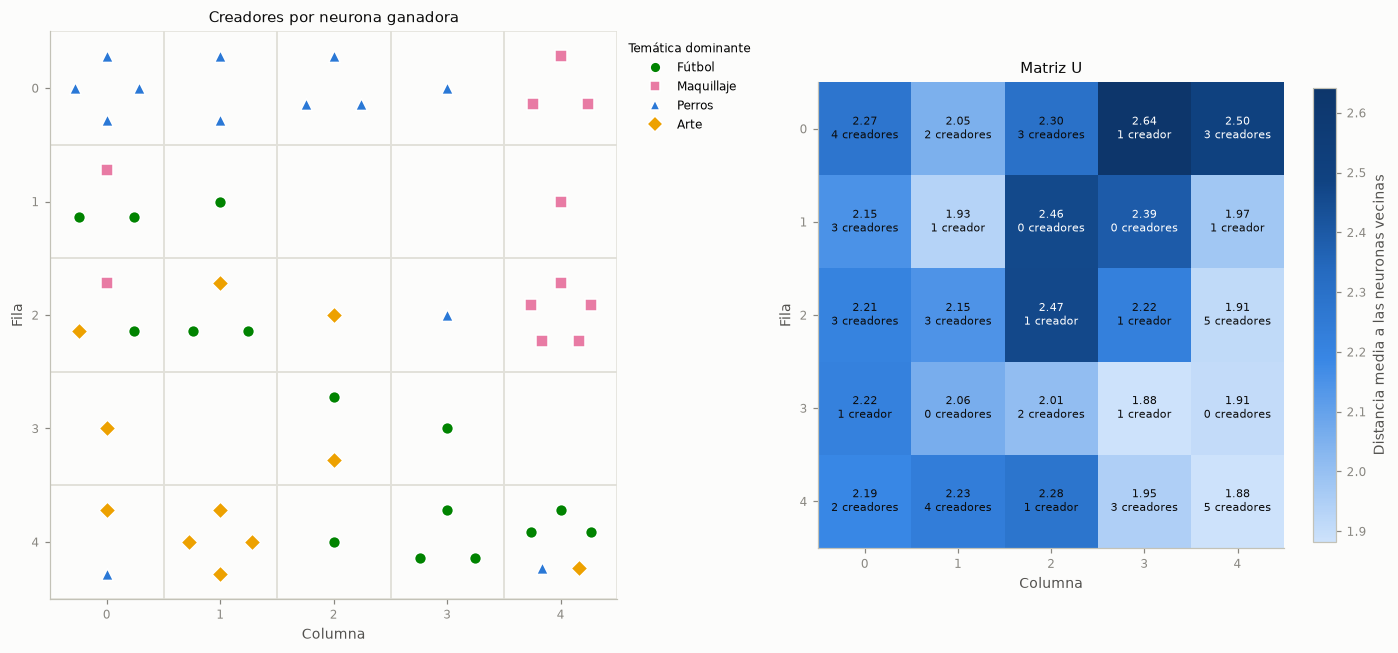

In [12]:
som = Kohonen(**BASE, seed=0).fit(X)
print(f"QE = {som.quantization_error(X):.3f} | TE = {som.topographic_error(X):.0%} | "
      f"varianza explicada = {explained_variance(som, X):.1%} | "
      f"neuronas vacías = {int((som.hits(X) == 0).sum())}/{som.n_neurons}")
plots.plot_som_maps(som, X, data.topic)
plt.show()

La **matriz U** muestra, para cada neurona, la distancia media entre su prototipo y los de sus vecinas. **Una distancia alta indica una frontera**: dos neuronas contiguas en la grilla representan creadores muy distintos, y pasar de una a otra es un cambio de perfil. Valores bajos indican zonas homogéneas, donde los creadores vecinos se parecen.

- **Distribución:** las temáticas ocupan zonas contiguas. Perros está en la fila superior, maquillaje en la columna derecha, arte abajo a la izquierda y fútbol abajo y al centro. Las mezclas aparecen sobre todo en la esquina inferior derecha.
- **Fronteras:** los valores más altos están alrededor de la fila de perros y de la columna de maquillaje, incluidas las neuronas vacías del centro, (1,2) y (1,3). Esas neuronas no representan a ningún creador: funcionan como **separadores** entre perfiles.
- **Zonas homogéneas:** la esquina inferior derecha tiene los valores más bajos. Ahí los creadores masivos se parecen entre sí aunque publiquen sobre temas distintos.
- **Contraste moderado:** U va de ≈ 1,9 a ≈ 2,6. No hay grupos aislados por saltos grandes, sino un **continuo** con sub-regiones. Es coherente con el PCA, donde sólo PC1 se destaca claramente del azar.

## 9. Interpretación de las regiones

Los **planos de componentes** muestran el valor de cada variable en el prototipo de cada neurona. Leerlos juntos permite asignar un perfil a cada zona del mapa. Abajo, el mismo análisis con la proyección de cada prototipo sobre PC1–PC4.

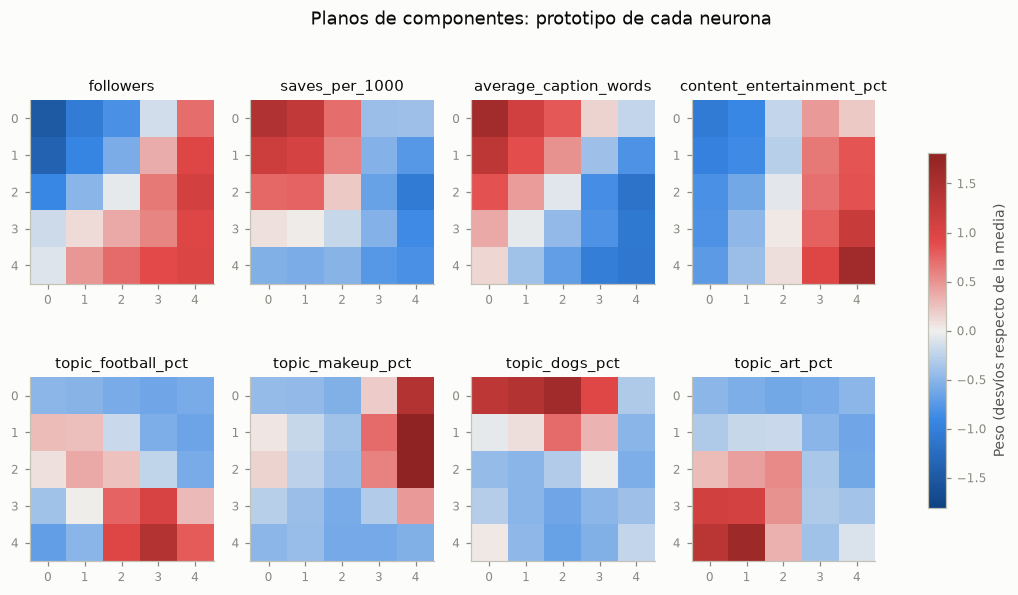

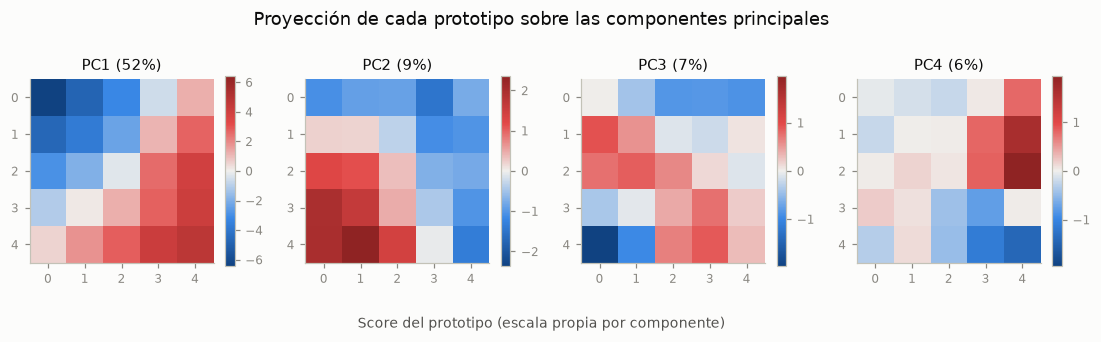

In [13]:
selected = ["followers", "saves_per_1000", "average_caption_words", "content_entertainment_pct",
            "topic_football_pct", "topic_makeup_pct", "topic_dogs_pct", "topic_art_pct"]
weights = som.weights_.reshape(som.rows, som.cols, -1)
plots.plot_planes(weights[:, :, [features.index(v) for v in selected]], selected,
                  "Planos de componentes: prototipo de cada neurona", "Peso (desvíos respecto de la media)")
plt.show()

prototype_scores = pca.transform(som.weights_)[:, :4].reshape(som.rows, som.cols, 4)
plots.plot_planes(prototype_scores, [f"PC{k + 1} ({explained[k]:.0%})" for k in range(4)],
                  "Proyección de cada prototipo sobre las componentes principales",
                  "Score del prototipo (escala propia por componente)", shared_scale=False)
plt.show()

A partir de los planos se delimitan cinco regiones contiguas de la grilla. Para cada una se resume el perfil en unidades originales (mediana de los creadores asignados):

In [14]:
REGIONS = {
    "Perros: comunidad y profundidad": [(0, 0), (0, 1), (0, 2), (0, 3)],
    "Nicho profundo (fútbol y mixto)": [(1, 0), (1, 1), (2, 0), (2, 1)],
    "Arte: mostrar y reseñar": [(2, 2), (3, 0), (4, 0), (4, 1)],
    "Maquillaje masivo": [(0, 4), (1, 4), (2, 4)],
    "Masivo y descubrimiento": [(2, 3), (3, 2), (3, 3), (4, 2), (4, 3), (4, 4)],
}
cell_of = {tuple(int(v) for v in som.positions_[n]): n for n in range(som.n_neurons)}
neuron_region = {cell_of[cell]: name for name, cells in REGIONS.items() for cell in cells}
winners = som.predict(X)
region = pd.Series([neuron_region.get(n, "sin región") for n in winners], name="región")
assert (region != "sin región").all()

profile_columns = ["followers", "price_usd", "non_follower_reach_pct", "saves_per_1000",
                   "profile_visits_per_1000", "average_caption_words", "content_entertainment_pct",
                   "argentina_audience_pct", "sponsored_posts_pct"]
profiles = df[profile_columns].groupby(region).median()
profiles.insert(0, "creadores", region.value_counts())
profiles.insert(1, "temáticas", data.topic.groupby(region).agg(
    lambda s: ", ".join(f"{t} {n}" for t, n in s.value_counts().items())))
profiles["PC1 medio"] = pd.Series(scores[:, 0]).groupby(region).mean()
profiles["PC2 medio"] = pd.Series(scores[:, 1]).groupby(region).mean()
display(profiles.loc[list(REGIONS)])

,creadores,temáticas,followers,price_usd,non_follower_reach_pct,saves_per_1000,profile_visits_per_1000,average_caption_words,content_entertainment_pct,argentina_audience_pct,sponsored_posts_pct,PC1 medio,PC2 medio
región,,,,,,,,,,,,,
Perros: comunidad y profundidad,10,Perros 10,"34,080.000",203.970,39.030,19.835,22.425,159.020,3.980,68.745,10.225,-4.727,-1.302
Nicho profundo (fútbol y mixto),10,"Fútbol 6, Arte 2, Maquillaje 2","35,756.000",256.070,45.980,18.915,19.405,144.455,9.455,47.865,48.050,-3.146,0.961
Arte: mostrar y reseñar,8,"Arte 7, Perros 1","229,399.500","1,290.660",55.490,12.305,18.830,101.150,14.535,34.515,40.515,0.788,2.044
Maquillaje masivo,9,Maquillaje 9,"426,362.000","2,783.980",63.050,9.920,13.360,56.190,59.000,36.440,15.010,2.968,-0.740
Masivo y descubrimiento,13,"Fútbol 9, Perros 2, Arte 2","349,287.000","3,251.200",76.210,9.960,13.060,60.810,61.260,59.810,39.020,3.516,-0.483


### ¿Qué perfiles reúne cada región?

| Región | Perfil |
|---|---|
| **Perros: comunidad y profundidad** (fila superior) | Los creadores más chicos y baratos, con mayor audiencia argentina, textos largos, tutoriales y la mayor tasa de guardados y visitas al perfil. Es el polo "profundo" de PC1. |
| **Nicho profundo** (arriba a la izquierda, debajo de perros) | Creadores chicos de fútbol, con algunos de maquillaje y arte: alta interacción de intención y más contenido patrocinado. |
| **Arte: mostrar y reseñar** (abajo a la izquierda) | Contenido que muestra resultados y reseña materiales, de tamaño intermedio. Es el polo positivo de PC2. |
| **Maquillaje masivo** (columna derecha) | Maquillaje con muchos seguidores, entretenimiento y videos cortos, y pocos guardados y comentarios. |
| **Masivo y descubrimiento** (abajo a la derecha) | Los creadores más grandes y caros, con alto alcance a no seguidores y contenido de entretenimiento. Es mayoritariamente fútbol, pero también reúne perros y arte: **a esta escala la temática pesa menos que el tamaño**. |

### ¿Coinciden con PC1 y PC2?

Sí. El plano de **PC1** crece en diagonal, de la esquina superior izquierda (perros profundos, PC1 ≈ −6) a la inferior derecha (masivos, PC1 ≈ +5): la red reproduce el eje masivo ↔ profundo sin haber recibido información del PCA. **PC2** crece hacia abajo a la izquierda (arte) y es mínimo en la fila de perros y en la columna derecha (maquillaje y entretenimiento), igual que en el biplot.

El mapa además separa perfiles que en el plano PC1–PC2 se superponen: **maquillaje** (alto en PC4) queda aislado en la columna derecha, y **fútbol** (alto en PC3) se separa de perros y de arte. Una grilla 2D no lineal resume información que en el PCA está repartida en ≈ 4 componentes: 72 % de varianza explicada contra 61 % del plano PC1–PC2.

### ¿Qué indica una distancia alta en la matriz U?

Que dos neuronas vecinas en la grilla tienen prototipos muy distintos: es una **frontera entre perfiles de creadores**. Para la agencia, elegir un creador "del otro lado" de una frontera alta es cambiar de tipo de audiencia y contenido, aunque en la grilla estén cerca. Las distancias bajas indican creadores intercambiables: si uno no está disponible, otro de la misma zona es un reemplazo razonable.

## 10. Conclusiones del 1.2

- **Modelo elegido:** grilla 5×5, $\eta_0 = 0{,}5$, $R_0 = 2{,}5 \rightarrow R_{\text{final}} = 0{,}5$, 100 épocas. Reproduce ≈ 72 % de la varianza, con error topográfico nulo y resultados estables entre semillas. El tamaño se eligió por el compromiso entre QE y neuronas vacías, no por el QE mínimo.
- **Estructura:** el mapa ordena a los creadores sobre el eje masivo ↔ profundo (PC1, en diagonal) y separa las temáticas en sub-regiones (PC2–PC4). La matriz U muestra un continuo con fronteras moderadas, no grupos aislados.
- **Limitación:** el bloque de tamaño (5 variables casi iguales) pesa mucho en la distancia euclídea. Por eso, en la región masiva, los creadores se agrupan por tamaño antes que por temática.
- **Para las campañas:** cada cliente encuentra su candidato en una región distinta. Un refugio, en la fila de perros. Una marca de arte, en la región de mostrar y reseñar. Una de maquillaje debe elegir entre la columna masiva y las neuronas de nicho. Elegir sólo por seguidores lleva siempre a la región masiva, cualquiera sea el cliente.